In [1]:
import pandas as pd
print(pd.__version__)

3.1.1


In [2]:
import pandas as pd

pokemon = pd.read_csv("pokemon.csv")
combats = pd.read_csv("combats.csv")

In [3]:
pokemon.head()

,#,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False
3,4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False
4,5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False


In [4]:
combats.head()

,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151


In [5]:
print(pokemon.shape)
print(combats.shape)

(800, 12)
(50000, 3)


In [6]:
pokemon.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           800 non-null    int64
 1   Name        799 non-null    str  
 2   Type 1      800 non-null    str  
 3   Type 2      414 non-null    str  
 4   HP          800 non-null    int64
 5   Attack      800 non-null    int64
 6   Defense     800 non-null    int64
 7   Sp. Atk     800 non-null    int64
 8   Sp. Def     800 non-null    int64
 9   Speed       800 non-null    int64
 10  Generation  800 non-null    int64
 11  Legendary   800 non-null    bool 
dtypes: bool(1), int64(8), str(3)
memory usage: 69.7 KB


In [7]:
pokemon.describe()

,#,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,400.5000,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,231.0844,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,1.0000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,200.7500,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,400.5000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,600.2500,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,800.0000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000


In [8]:
combats.head()

,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151


In [9]:
pokemon.head()

,#,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False
3,4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False
4,5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False


In [10]:
stats = pokemon.rename(columns={"#": "id"})
stat_cols = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
stats = stats[["id"] + stat_cols]
stats.head()

,id,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,1,45,49,49,65,65,45
1,2,60,62,63,80,80,60
2,3,80,82,83,100,100,80
3,4,80,100,123,122,120,80
4,5,39,52,43,60,50,65


In [11]:
first = stats.add_prefix("first_")
second = stats.add_prefix("second_")
first.head()

,first_id,first_HP,first_Attack,first_Defense,first_Sp. Atk,first_Sp. Def,first_Speed
0,1,45,49,49,65,65,45
1,2,60,62,63,80,80,60
2,3,80,82,83,100,100,80
3,4,80,100,123,122,120,80
4,5,39,52,43,60,50,65


In [12]:
data = combats.merge(first, left_on="First_pokemon", right_on="first_id", how="left")
data = data.merge(second, left_on="Second_pokemon", right_on="second_id", how="left")
data.head()

,First_pokemon,Second_pokemon,Winner,first_id,first_HP,first_Attack,first_Defense,first_Sp. Atk,first_Sp. Def,first_Speed,second_id,second_HP,second_Attack,second_Defense,second_Sp. Atk,second_Sp. Def,second_Speed
0,266,298,298,266,50,64,50,45,50,41,298,70,70,40,60,40,60
1,702,701,701,702,91,90,72,90,129,108,701,91,129,90,72,90,108
2,191,668,668,191,55,40,85,80,105,40,668,75,75,75,125,95,40
3,237,683,683,237,40,40,40,70,40,20,683,77,120,90,60,90,48
4,151,231,151,151,70,60,125,115,70,55,231,20,10,230,10,230,5


In [13]:
data["first_wins"] = (data["Winner"] == data["First_pokemon"]).astype(int)
data.head()

,First_pokemon,Second_pokemon,Winner,first_id,first_HP,first_Attack,first_Defense,first_Sp. Atk,first_Sp. Def,first_Speed,second_id,second_HP,second_Attack,second_Defense,second_Sp. Atk,second_Sp. Def,second_Speed,first_wins
0,266,298,298,266,50,64,50,45,50,41,298,70,70,40,60,40,60,0
1,702,701,701,702,91,90,72,90,129,108,701,91,129,90,72,90,108,0
2,191,668,668,191,55,40,85,80,105,40,668,75,75,75,125,95,40,0
3,237,683,683,237,40,40,40,70,40,20,683,77,120,90,60,90,48,0
4,151,231,151,151,70,60,125,115,70,55,231,20,10,230,10,230,5,1


In [14]:
data = data.drop(columns=["First_pokemon", "Second_pokemon", "Winner", "first_id", "second_id"])
print(data.shape)
data.head()

(50000, 13)


,first_HP,first_Attack,first_Defense,first_Sp. Atk,first_Sp. Def,first_Speed,second_HP,second_Attack,second_Defense,second_Sp. Atk,second_Sp. Def,second_Speed,first_wins
0,50,64,50,45,50,41,70,70,40,60,40,60,0
1,91,90,72,90,129,108,91,129,90,72,90,108,0
2,55,40,85,80,105,40,75,75,75,125,95,40,0
3,40,40,40,70,40,20,77,120,90,60,90,48,0
4,70,60,125,115,70,55,20,10,230,10,230,5,1


In [15]:
print(data.isna().sum())
print(data["first_wins"].mean())

first_HP          0
first_Attack      0
first_Defense     0
first_Sp. Atk     0
first_Sp. Def     0
first_Speed       0
second_HP         0
second_Attack     0
second_Defense    0
second_Sp. Atk    0
second_Sp. Def    0
second_Speed      0
first_wins        0
dtype: int64
0.47202


In [16]:
import matplotlib.pyplot as plt

diffs = pd.DataFrame()
for col in stat_cols:
    diffs[col] = data["first_" + col] - data["second_" + col]

diffs.head()

Matplotlib is building the font cache; this may take a moment.


,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed
0,-20,-6,10,-15,10,-19
1,0,-39,-18,18,39,0
2,-20,-35,10,-45,10,0
3,-37,-80,-50,10,-50,-28
4,50,50,-105,105,-160,50


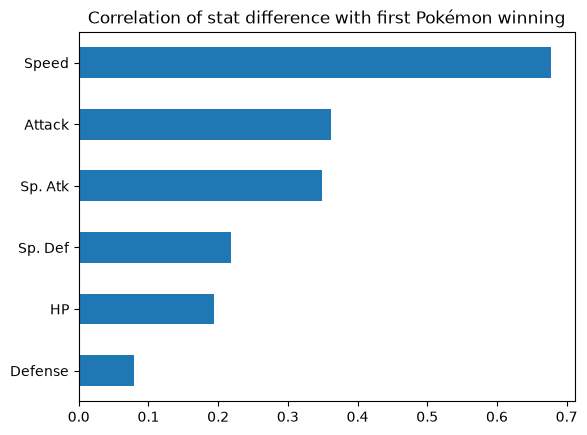

In [17]:
corr = diffs.corrwith(data["first_wins"]).sort_values()
corr.plot(kind="barh")
plt.title("Correlation of stat difference with first Pokémon winning")
plt.show()

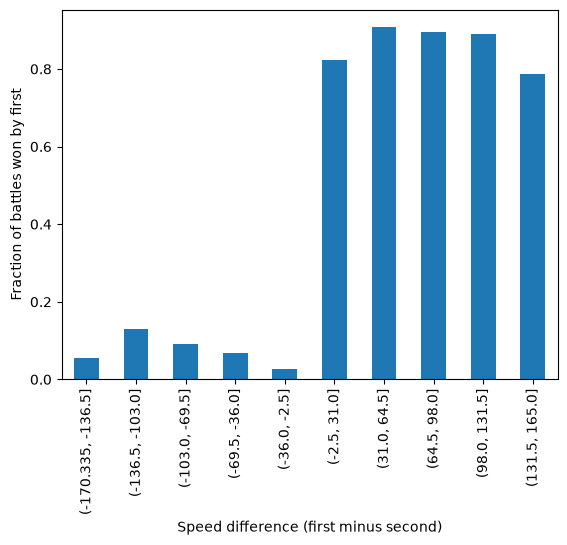

In [18]:
bins = pd.cut(diffs["Speed"], bins=10)
win_rate = data.groupby(bins, observed=True)["first_wins"].mean()
win_rate.plot(kind="bar")
plt.xlabel("Speed difference (first minus second)")
plt.ylabel("Fraction of battles won by first")
plt.show()

In [19]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["first_wins"])
y = data["first_wins"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(40000, 12) (10000, 12)


In [20]:
print(y_test.mean())

0.4753


In [21]:
X_train.describe()

,first_HP,first_Attack,first_Defense,first_Sp. Atk,first_Sp. Def,first_Speed,second_HP,second_Attack,second_Defense,second_Sp. Atk,second_Sp. Def,second_Speed
count,40000.000000,40000.000000,40000.000000,40000.00000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,69.112700,79.103100,74.249750,72.90775,72.093325,68.272375,69.098225,79.022075,74.219475,72.727450,72.117425,68.301650
std,25.283857,32.695627,31.517978,32.76830,27.835059,29.360536,25.123825,32.317246,31.605422,32.668324,27.836526,29.128807
min,1.000000,5.000000,5.000000,10.00000,20.000000,5.000000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000
25%,50.000000,55.000000,50.000000,50.00000,50.000000,45.000000,50.000000,55.000000,50.000000,50.000000,50.000000,45.000000
50%,65.000000,75.000000,70.000000,65.00000,70.000000,65.000000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000
75%,80.000000,100.000000,90.000000,95.00000,90.000000,90.000000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000
max,255.000000,190.000000,230.000000,194.00000,230.000000,180.000000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000


In [22]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [23]:
from sklearn.metrics import accuracy_score

train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print("Train accuracy:", accuracy_score(y_train, train_pred))
print("Test accuracy:", accuracy_score(y_test, test_pred))

Train accuracy: 0.864925
Test accuracy: 0.8632


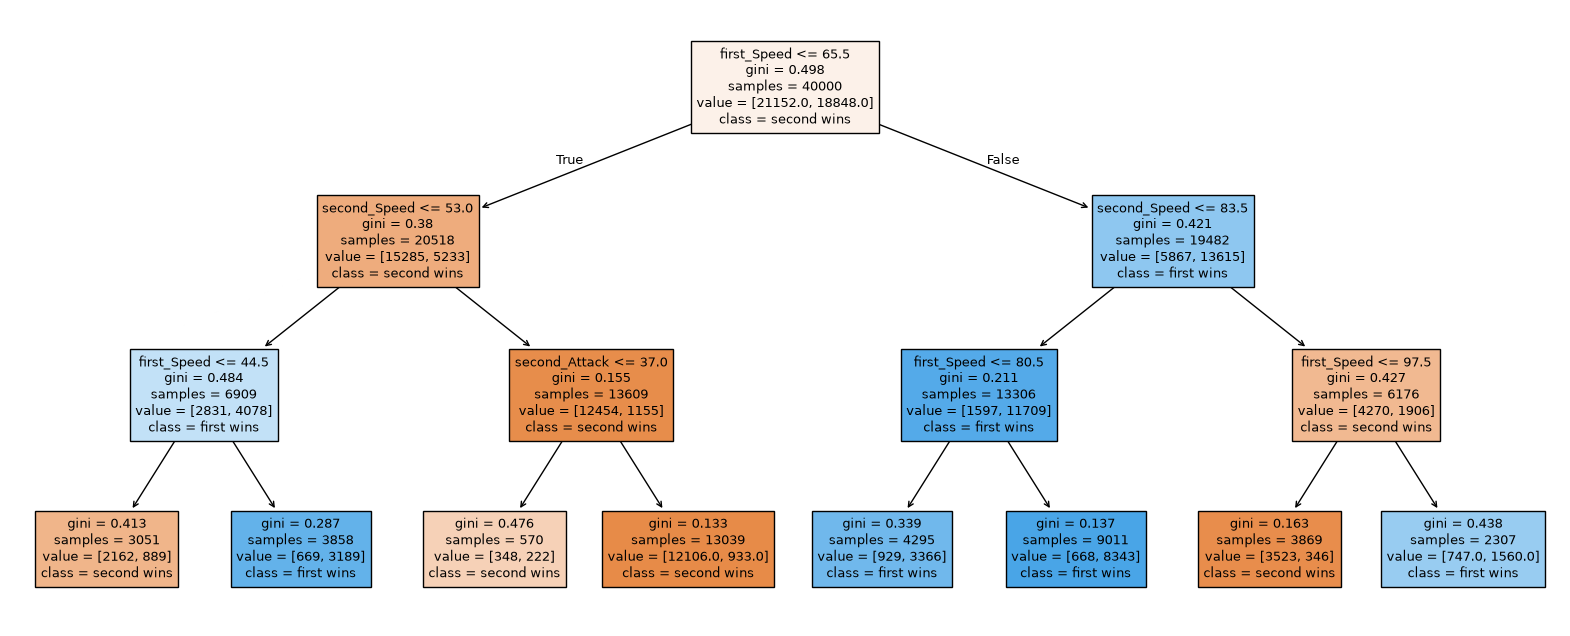

In [24]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(model, feature_names=X.columns, class_names=["second wins", "first wins"],
          filled=True, fontsize=9)
plt.show()

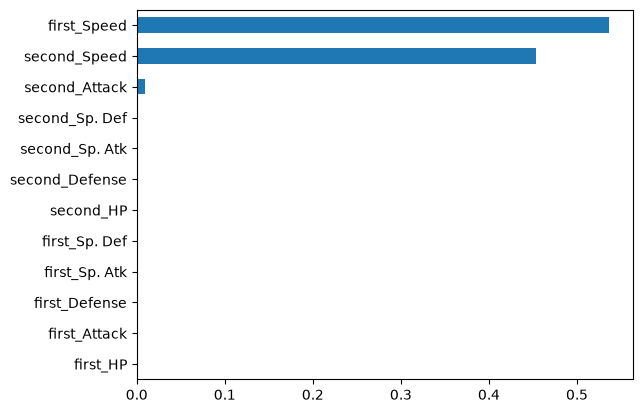

In [25]:
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh")
plt.show()

In [26]:
for depth in [1, 2, 3, 5, 8, 12, 20, None]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=42)
    m.fit(X_train, y_train)
    tr = accuracy_score(y_train, m.predict(X_train))
    te = accuracy_score(y_test, m.predict(X_test))
    print(f"depth={depth}: train={tr:.3f}  test={te:.3f}")

depth=1: train=0.723  test=0.712
depth=2: train=0.813  test=0.813
depth=3: train=0.865  test=0.863
depth=5: train=0.914  test=0.913
depth=8: train=0.948  test=0.942
depth=12: train=0.971  test=0.935
depth=20: train=0.997  test=0.923
depth=None: train=1.000  test=0.922


In [27]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

scores = cross_val_score(
    DecisionTreeClassifier(max_depth=8, random_state=42),
    X_train, y_train, cv=5
)
print(scores)
print("Average:", scores.mean())

[0.938625 0.93575  0.935375 0.93975  0.9375  ]
Average: 0.9374


In [28]:
for depth in [3, 5, 8, 12, 20]:
    s = cross_val_score(
        DecisionTreeClassifier(max_depth=depth, random_state=42),
        X_train, y_train, cv=5
    )
    print(f"depth={depth}: cv accuracy={s.mean():.3f}")

depth=3: cv accuracy=0.861
depth=5: cv accuracy=0.914
depth=8: cv accuracy=0.937
depth=12: cv accuracy=0.934
depth=20: cv accuracy=0.921


In [29]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
scores = cross_val_score(forest, X_train, y_train, cv=5)
print("Forest cv accuracy:", scores.mean())

Forest cv accuracy: 0.945


In [30]:
def add_diffs(df):
    out = df.copy()
    for col in stat_cols:
        out["diff_" + col] = df["first_" + col] - df["second_" + col]
    return out

X_train_fe = add_diffs(X_train)
X_test_fe = add_diffs(X_test)
print(X_train_fe.shape)

(40000, 18)


In [31]:
scores_fe = cross_val_score(forest, X_train_fe, y_train, cv=5)
print("Forest cv accuracy with diffs:", scores_fe.mean())

Forest cv accuracy with diffs: 0.9531500000000002


In [32]:
final_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
final_model.fit(X_train_fe, y_train)

print("Test accuracy:", accuracy_score(y_test, final_model.predict(X_test_fe)))

Test accuracy: 0.9558


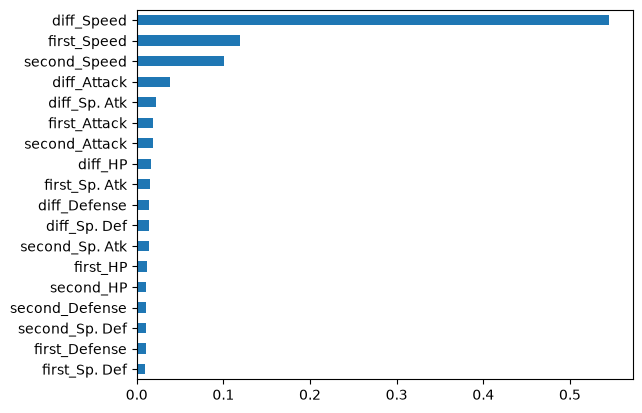

In [33]:
imp = pd.Series(final_model.feature_importances_, index=X_train_fe.columns).sort_values()
imp.plot(kind="barh")
plt.show()

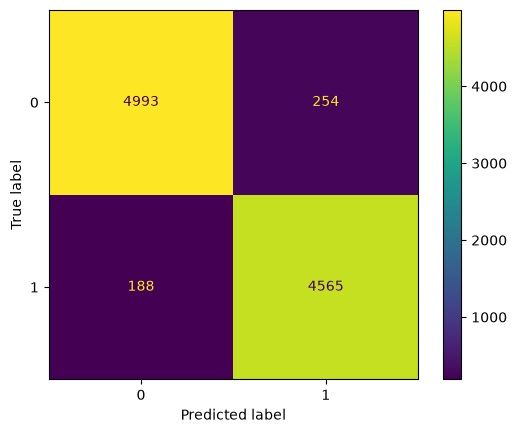

              precision    recall  f1-score   support

           0       0.96      0.95      0.96      5247
           1       0.95      0.96      0.95      4753

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



In [34]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

test_pred = final_model.predict(X_test_fe)

ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.show()

print(classification_report(y_test, test_pred))

In [35]:
wrong = test_pred != y_test.values
errors = X_test_fe[wrong]

print("Number of mistakes:", wrong.sum())
print("Avg |speed difference| on mistakes:", errors["diff_Speed"].abs().mean())
print("Avg |speed difference| overall:   ", X_test_fe["diff_Speed"].abs().mean())

Number of mistakes: 442
Avg |speed difference| on mistakes: 43.432126696832576
Avg |speed difference| overall:    32.9599


In [36]:
import joblib
import json

joblib.dump(final_model, "model.joblib")

with open("feature_columns.json", "w") as f:
    json.dump(list(X_train_fe.columns), f)

In [37]:
loaded = joblib.load("model.joblib")

one_battle = X_test_fe.iloc[[0]]
print(one_battle)
print("Prediction:", loaded.predict(one_battle))
print("Probabilities:", loaded.predict_proba(one_battle))
print("Actual:", y_test.iloc[0])

       first_HP  first_Attack  first_Defense  first_Sp. Atk  first_Sp. Def  \
33553        85           115             80            105             80   

       first_Speed  second_HP  second_Attack  second_Defense  second_Sp. Atk  \
33553           50         80             80              80              80   

       second_Sp. Def  second_Speed  diff_HP  diff_Attack  diff_Defense  \
33553              80            80        5           35             0   

       diff_Sp. Atk  diff_Sp. Def  diff_Speed  
33553            25             0         -30  
Prediction: [0]
Probabilities: [[1. 0.]]
Actual: 0
